# Rôle 3 : recherche de passages (`retrieve`)

`retrieve(question, k)` rend les `k` passages des documents de projets les plus proches d'une question. L'agent s'en sert pour citer les dossiers dans sa recommandation (principe du **RAG** : on cherche d'abord des passages, le LLM rédige ensuite à partir d'eux).

On compare :

- **TF-IDF** (modèle de référence) : chaque passage est un vecteur de mots pondérés, la similarité est le cosinus entre la question et le passage. Seuls les mots communs comptent.
- **Embeddings** (modèle avancé) : un petit réseau de neurones pré-entraîné (`all-MiniLM-L6-v2`, 22 millions de paramètres, local, sur processeur) transforme chaque passage en un vecteur de 384 nombres qui résume son sens. Deux textes de même sens ont des vecteurs proches, même sans mot commun.
- **Hybride** : moyenne pondérée des deux scores, `alpha * embeddings + (1 - alpha) * TF-IDF`.

**Pas d'apprentissage, donc pas de fuite à craindre du côté des modèles** : le modèle d'embeddings est utilisé tel quel, et le vocabulaire TF-IDF est construit sur les passages à chercher, sans aucune étiquette. La seule chose réglée est `alpha`, sur un jeu de requêtes séparé du jeu de test.

In [1]:
import logging
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
sys.path.insert(0, str(RACINE / "scripts"))
from src import nlp
import evaluer_retrieve_nlp as ev

FIGURES = RACINE / "reports" / "role3" / "figures"
ANNOT = RACINE / "reports" / "role3" / "annotations"
logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Construction des index et vitesse

In [2]:
documents = nlp.charger_documents()
t = time.perf_counter(); tfidf = nlp.construire_index("tfidf", documents); t_tfidf = time.perf_counter() - t
t = time.perf_counter(); emb = nlp.construire_index("embeddings", documents); t_emb = time.perf_counter() - t
print(f"{len(tfidf.passages):,} passages")
print(f"TF-IDF : index construit en {t_tfidf:.1f} s, matrice {tfidf.matrice.shape}")
print(f"Embeddings : index chargé en {t_emb:.1f} s (vecteurs déjà calculés et enregistrés dans models/nlp/), matrice {emb.matrice.shape}")
for nom, idx in (("TF-IDF", tfidf), ("Embeddings", emb)):
    t = time.perf_counter()
    for _ in range(20):
        nlp.chercher(idx, "access to finance for small businesses", 3)
    print(f"{nom} : {(time.perf_counter() - t) / 20 * 1000:.0f} ms par question")

C:\Users\Ilyas BEN ALLA\Documents\role3-nlp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2639.22it/s]

8,293 passages
TF-IDF : index construit en 4.4 s, matrice (8293, 165645)
Embeddings : index chargé en 11.5 s (vecteurs déjà calculés et enregistrés dans models/nlp/), matrice (8293, 384)
TF-IDF : 5 ms par question


Embeddings : 20 ms par question


Le premier calcul des embeddings des 8 293 passages prend environ 4 minutes sur un portable sans GPU. Il n'est fait qu'une fois : les vecteurs sont enregistrés sur disque (dossier `models/nlp/`, ignoré par Git) avec une empreinte du corpus, et recalculés seulement si les documents ou le découpage changent. Ensuite, une question prend quelques millisecondes.

## 2. Requêtes de test et jugements de pertinence

40 requêtes écrites à la main, en anglais comme les documents, couvrant les 11 secteurs. Elles sont **reformulées** pour ne pas recopier les mots des documents (par exemple « getting more girls to attend secondary school »), sinon TF-IDF serait avantagé.

- 15 requêtes de **réglage** : servent à choisir `alpha` ;
- 25 requêtes de **test** : servent seulement à la mesure finale.

**Projets attendus.** Il est impossible de juger 2 000 documents pour chaque requête. On utilise la mise en commun des candidats (*pooling*, méthode des campagnes d'évaluation TREC) : pour chaque requête, on réunit les 10 premiers projets de TF-IDF, les 10 premiers des embeddings, et jusqu'à 10 projets dont le titre contient un synonyme choisi à l'avance (`scripts/candidats_retrieve_nlp.py`). Chaque candidat est jugé pertinent si son objectif principal, ou une composante majeure, traite directement le sujet de la requête.

In [3]:
requetes = pd.read_csv(ANNOT / "requetes_retrieve.csv")
juges = pd.read_csv(ANNOT / "jugements_retrieve.csv")
jugements = juges[juges.pertinent == 1].groupby("id_requete")["id_projet"].apply(set).to_dict()
print(f"{len(juges)} candidats jugés, {juges.pertinent.sum()} pertinents")
print("projets pertinents par requête :", pd.Series({r: len(s) for r, s in jugements.items()}).describe()[["min", "50%", "max"]].to_dict())
requetes.groupby("jeu").head(3)

886 candidats jugés, 489 pertinents
projets pertinents par requête : {'min': 4.0, '50%': 12.0, 'max': 21.0}


,id_requete,jeu,requete
0,R01,reglage,rural electrification with solar mini-grids
1,R02,reglage,improving learning outcomes in primary schools
2,R03,reglage,reducing child malnutrition and stunting
15,R16,test,helping farmers cope with drought
16,R17,test,getting more girls to attend secondary school
17,R18,test,reducing deaths of mothers and newborns


## 3. Mesures

Au niveau des **projets** (un passage par projet dans la liste rendue) :

- **précision@k** : part de projets pertinents parmi les `k` premiers. C'est la mesure qui compte pour l'agent, qui lit les 3 premiers passages ;
- **MRR** (*mean reciprocal rank*) : moyenne de 1 / rang du premier projet pertinent. 1 si le premier résultat est toujours bon, 0,5 s'il arrive en moyenne au rang 2 ;
- **rappel@10** : part des projets pertinents connus retrouvés dans les 10 premiers.

## 4. Réglage de `alpha` (15 requêtes de réglage)

,alpha,precision@3,mrr
0,0.0,0.800,0.956
1,0.2,0.867,0.956
2,0.4,0.889,0.967
3,0.5,0.889,0.967
4,0.6,0.933,0.933
5,0.7,0.911,0.967
6,0.8,0.911,0.933
7,0.9,0.911,0.933
8,1.0,0.911,0.967


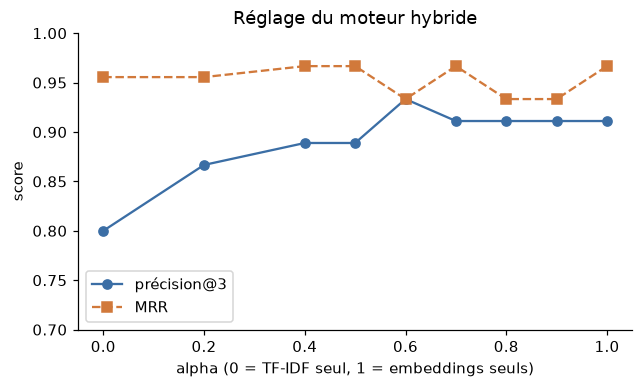

In [4]:
reglage = requetes[requetes.jeu == "reglage"]
choix = pd.DataFrame([{"alpha": a, **ev.evaluer(nlp.IndexHybride(tfidf, emb, a), reglage, jugements)[["precision@3", "mrr"]].mean()}
                      for a in ev.ALPHAS])
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(choix.alpha, choix["precision@3"], "o-", label="précision@3", color="#3b6ea5")
ax.plot(choix.alpha, choix["mrr"], "s--", label="MRR", color="#d1793b")
ax.set(title="Réglage du moteur hybride", xlabel="alpha (0 = TF-IDF seul, 1 = embeddings seuls)", ylabel="score", ylim=(0.7, 1.0))
ax.legend()
fig.savefig(FIGURES / "reglage_alpha.png", bbox_inches="tight")
choix.round(3)

Sur le réglage, `alpha = 0,6` arrive en tête en précision@3 (0,933), juste devant les embeddings seuls (0,911). L'écart vaut **un seul bon résultat sur 45** : trop peu pour préférer un modèle plus compliqué. On garde les deux pour le test, en notant que le choix entre eux n'est pas tranché par le réglage.

## 5. Résultats sur les 25 requêtes de test

In [5]:
moteurs = {"tfidf": tfidf, "embeddings": emb, "hybride": nlp.IndexHybride(tfidf, emb, 0.6)}
detail = pd.concat([ev.evaluer(idx, requetes, jugements).assign(moteur=nom) for nom, idx in moteurs.items()])
test = detail[detail.jeu == "test"]
resume = test.groupby("moteur")[["precision@3", "precision@5", "mrr", "rappel@10"]].mean().loc[list(moteurs)]
resume.round(3)

,precision@3,precision@5,mrr,rappel@10
moteur,,,,
tfidf,0.547,0.536,0.721,0.475
embeddings,0.747,0.776,0.933,0.649
hybride,0.707,0.672,0.878,0.616


In [6]:
pivot = test.pivot(index="id_requete", columns="moteur", values="precision@3")
lignes = []
for a, b in (("embeddings", "tfidf"), ("hybride", "embeddings"), ("hybride", "tfidf")):
    bas, haut = ev.intervalle_difference(pivot[a], pivot[b])
    lignes.append({"comparaison": f"{a} - {b}", "écart moyen": (pivot[a] - pivot[b]).mean(), "IC 95 % bas": bas,
                   "IC 95 % haut": haut, "requêtes gagnées": int((pivot[a] > pivot[b]).sum()),
                   "requêtes perdues": int((pivot[a] < pivot[b]).sum())})
pd.DataFrame(lignes).round(3)

,comparaison,écart moyen,IC 95 % bas,IC 95 % haut,requêtes gagnées,requêtes perdues
0,embeddings - tfidf,0.20,0.080,0.333,12,3
1,hybride - embeddings,-0.04,-0.187,0.107,7,10
2,hybride - tfidf,0.16,0.053,0.267,11,2


L'intervalle de confiance est obtenu par **bootstrap** : on retire 5 000 fois au hasard 25 requêtes parmi les 25 (avec remise) et on regarde comment varie l'écart moyen. S'il ne contient pas 0, l'écart n'est pas dû au choix des requêtes.

- **Embeddings contre TF-IDF** : +0,20 de précision@3, intervalle entièrement positif. Les embeddings sont nettement meilleurs.
- **Hybride contre embeddings** : écart négatif mais intervalle qui contient 0. Pas de différence démontrable.

**Choix final : embeddings seuls.** À égalité sur le réglage, on préfère le modèle le plus simple ; le test confirme qu'on ne perd rien. Les deux autres moteurs restent disponibles (`NLP_RETRIEVE=tfidf`), et TF-IDF sert de repli automatique si le modèle d'embeddings ne peut pas être chargé.

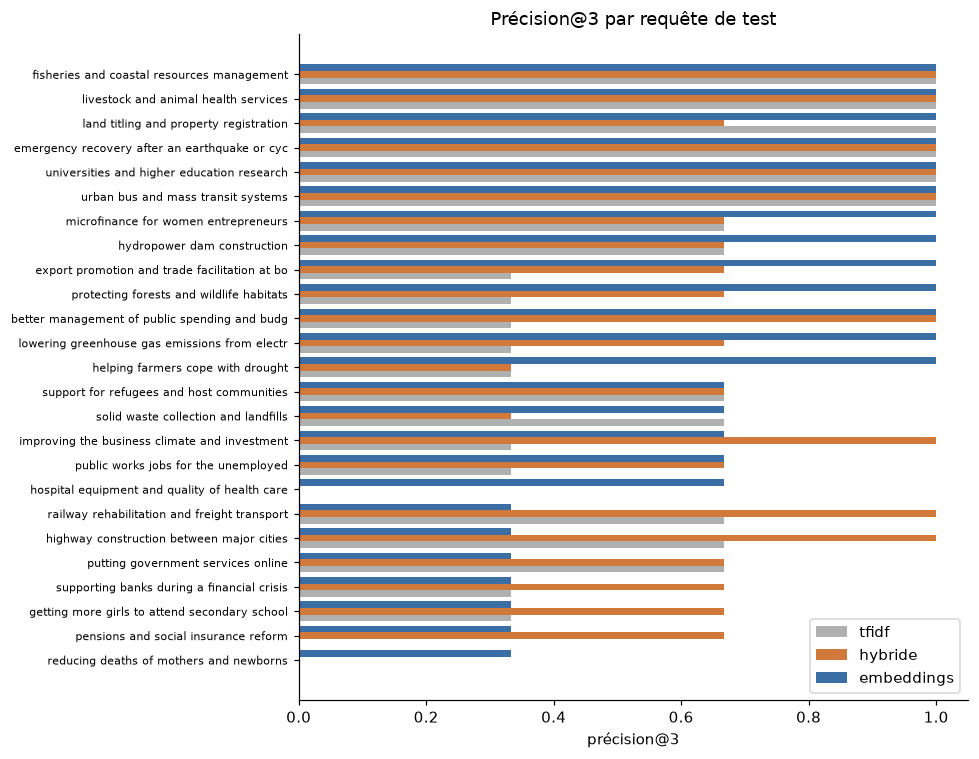

In [7]:
ordre = pivot.sort_values(["embeddings", "tfidf"]).index
textes = requetes.set_index("id_requete").loc[ordre, "requete"]
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(ordre))
for decalage, (nom, couleur) in zip((-0.27, 0, 0.27), (("tfidf", "#b0b0b0"), ("hybride", "#d1793b"), ("embeddings", "#3b6ea5"))):
    ax.barh(y + decalage, pivot.loc[ordre, nom], height=0.27, color=couleur, label=nom)
ax.set_yticks(y, [t[:45] for t in textes], fontsize=7)
ax.set(title="Précision@3 par requête de test", xlabel="précision@3")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "precision_par_requete.png", bbox_inches="tight")

## 6. Analyse des erreurs

Où chaque moteur gagne-t-il ?

In [8]:
def montrer(question: str, k: int = 3) -> None:
    """Affiche les k premiers projets de chaque moteur, avec le jugement de pertinence."""
    id_req = requetes.loc[requetes.requete == question, "id_requete"].iloc[0]
    print(f"> {question}")
    for nom in ("tfidf", "embeddings"):
        print(f"  {nom}")
        for r in nlp.chercher(moteurs[nom], question, k):
            marque = "OK " if r["id_projet"] in jugements[id_req] else " x "
            print(f"    {marque} {r['id_projet']} {r['score']:.2f}  {nlp.titre(documents[r['id_projet']])[:65]}")
    print()

for q in ("helping farmers cope with drought", "lowering greenhouse gas emissions from electricity generation",
          "highway construction between major cities", "reducing deaths of mothers and newborns"):
    montrer(q)

> helping farmers cope with drought
  tfidf
     x  P167790 0.17  Higher Education Project
    OK  P173387 0.08  Early Warning, Early Finance and Early Action Project
     x  P179775 0.07  Somalia Urban Resilience Project Phase II Second Additional Finan
  embeddings
    OK  P104724 0.60  Andhra Pradesh Rural Poverty Reduction: Drought Adaptative Initia
    OK  P163260 0.60  DR Resilient Agriculture and Integrated Water Resources Managemen
    OK  P163533 0.57  Odisha Integrated Irrigation Project for Climate Resilient Agricu

> lowering greenhouse gas emissions from electricity generation
  tfidf
    OK  P120660 0.28  LIBERIA Electricity System Enhancement Project (LESEP)
     x  P132418 0.19  Efficient & Sustainable City Bus Services
     x  P119357 0.19  China Energy Efficiency Promotion in Industry
  embeddings
    OK  P098654 0.57  Thermal Power Efficiency
    OK  P120660 0.57  LIBERIA Electricity System Enhancement Project (LESEP)
    OK  P038121 0.52  CN-GEF-Renewable Energy Dev

**Lecture.**

- **Les embeddings gagnent quand la question est une reformulation.** « Helping farmers cope with drought » ne contient ni *climate*, ni *resilience*, ni *smart agriculture* ; les embeddings relient pourtant la sécheresse à la résilience climatique de l'agriculture. TF-IDF, lui, accroche des mots isolés.
- **TF-IDF résiste mieux sur un terme technique précis.** Pour « highway construction between major cities », les embeddings remontent des projets routiers généraux (entretien, routes en ville) : du bon domaine, mais pas des autoroutes entre villes. Le mot exact *highway* aide TF-IDF.
- **Les erreurs des embeddings sont des voisins de sujet**, pas des résultats absurdes : pour « reducing deaths of mothers and newborns », un projet de nutrition de la petite enfance arrive en 2e position.

C'est le comportement attendu d'un modèle qui compare le **sens** plutôt que les **mots** : plus robuste aux reformulations, un peu moins précis sur les termes techniques.

## 7. Limites

1. **Jugements de pertinence faits par une seule personne**, selon une règle stricte : une règle plus souple (par exemple accepter tout projet routier pour « highway ») ferait monter les scores. Les jugements sont publiés (`reports/role3/annotations/jugements_retrieve.csv`) et peuvent être vérifiés.
2. **Biais de la mise en commun des candidats** : un projet pertinent qu'aucune des trois sources n'a trouvé est compté comme non pertinent. TF-IDF et embeddings ont fourni autant de candidats chacun (10), donc la comparaison est équitable jusqu'au rang 10, mais le rappel est surestimé.
3. **25 requêtes de test**, d'où des intervalles de confiance larges.
4. **Requêtes de test plus difficiles que celles de réglage** (0,75 contre 0,91 en précision@3 pour les embeddings) : elles ont été plus reformulées. Le réglage d'`alpha` ne s'est pas transféré au test, ce qui illustre le risque de régler un paramètre sur peu de données.
5. Le modèle d'embeddings est **généraliste** et a été entraîné surtout sur de l'anglais courant : il ne connaît pas toujours les sigles de la Banque mondiale (*PforR, DPL, APL*).